Saving brain.jpg to brain.jpg


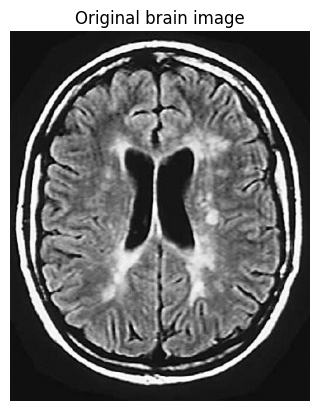

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
img = cv2.imread("brain.jpg", cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.title("Original brain image")
plt.axis("off");

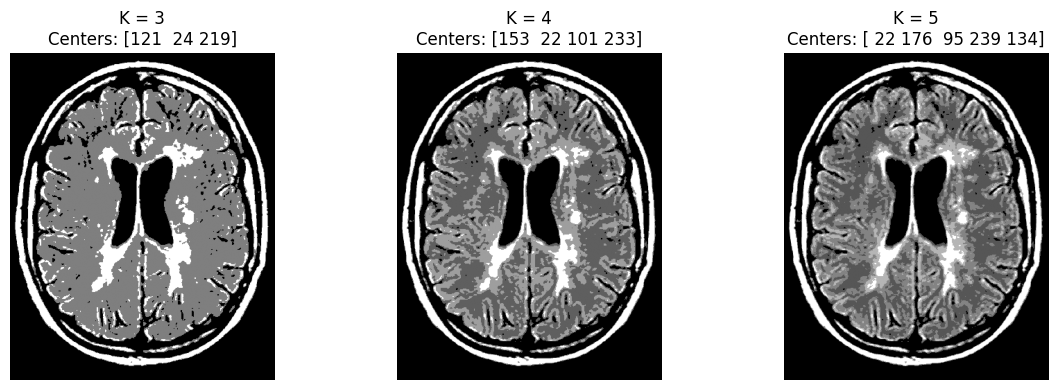

In [5]:
pixels = img.reshape((-1, 1)).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,100,0.2)
Ki = [3, 4, 5]
results = {}
plt.figure(figsize=(12, 4))
for i, K in enumerate(Ki):
    compactness, labels, centers = cv2.kmeans(pixels,K,None,criteria,10,cv2.KMEANS_PP_CENTERS)
    centers = np.uint8(centers)
    labels_2d = labels.reshape(img.shape)
    segmented = centers[labels.flatten()]
    segmented = segmented.reshape(img.shape)
    results[K] = {
        "segmented": segmented,
        "labels": labels_2d,
        "centers": centers.flatten()
    }
    plt.subplot(1, 3, i + 1)
    plt.imshow(segmented, cmap='gray')
    plt.title(f"K = {K}\nCenters: {centers.flatten()}")
    plt.axis("off")
plt.tight_layout()
plt.show()

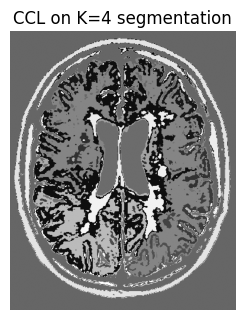

In [21]:
labels_k4 = results[4]["labels"]   # this contains the K-means labels: 0,1,2,3
ccl_result = np.zeros_like(labels_k4, dtype=np.int32)
current_label = 1
for k in range(4):
    mask = (labels_k4 == k).astype(np.uint8)
    num_labels, cc = cv2.connectedComponents(mask, connectivity=8)
    for i in range(1, num_labels):
        ccl_result[cc == i] = current_label
        current_label += 1
ccl_gray = np.uint8(255 * ccl_result / ccl_result.max())
plt.subplot(1,2,2)
plt.imshow(ccl_gray, cmap='gray')
plt.title("CCL on K=4 segmentation")
plt.axis("off")
plt.show()

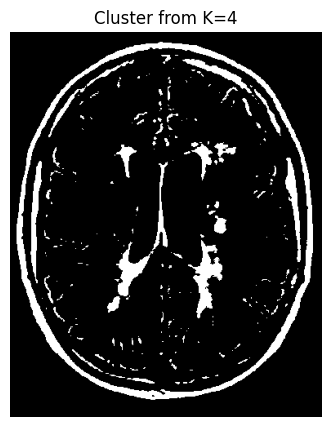

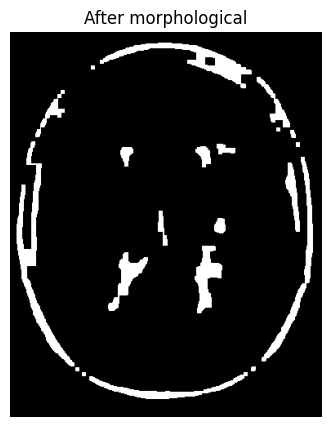

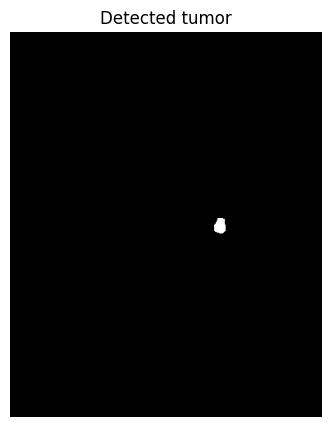

In [20]:
labels_k4 = results[4]["labels"]
centers_k4 = results[4]["centers"]
cluster = np.argmax(centers_k4)
tumor_mask = np.zeros_like(img, dtype=np.uint8)
tumor_mask[labels_k4 == cluster] = 255
plt.figure(figsize=(5,5))
plt.imshow(tumor_mask, cmap='gray')
plt.title("Cluster from K=4")
plt.axis("off");
kernel = np.ones((5,5), np.uint8)
clean = cv2.morphologyEx(tumor_mask, cv2.MORPH_OPEN, kernel, iterations=1)
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, kernel, iterations=2)
plt.figure(figsize=(5,5))
plt.imshow(clean, cmap='gray')
plt.title("After morphological")
plt.axis("off");
h, w = clean.shape
# Tumor is near the center right
target = np.array([0.62 * w, 0.48 * h])
best_label = None
best_distance = 1e9
for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    cx, cy = centroids[i]
    # Ignore huge skull ring and very tiny noise
    if 20 < area < 1000:
        distance = np.linalg.norm(np.array([cx, cy]) - target)
        if distance < best_distance:
            best_distance = distance
            best_label = i
tumor = np.zeros_like(img, dtype=np.uint8)
if best_label is not None:
    tumor[labels == best_label] = 255
plt.figure(figsize=(5,5))
plt.imshow(tumor, cmap='gray')
plt.title("Detected tumor")
plt.axis("off");